In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df = pd.read_csv(r"C:\Users\Lenovo\Downloads\heart_disease_practice.csv")
display(df.head(5))

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,max_heart_rate,exercise_angina,oldpeak,heart_disease
0,HD-2001,38,1,1,105,360,107,1,0.5,1
1,HD-2002,54,0,2,165,154,196,0,0.4,0
2,HD-2003,33,0,1,130,140,111,0,1.5,0
3,HD-2004,69,0,0,141,312,164,1,4.1,1
4,HD-2005,53,1,1,156,332,122,0,1.2,0


In [3]:
df.columns

Index(['patient_id', 'age', 'sex', 'chest_pain_type', 'resting_bp',
       'cholesterol', 'max_heart_rate', 'exercise_angina', 'oldpeak',
       'heart_disease'],
      dtype='str')

In [4]:
feature_cols = ['age', 'sex', 'chest_pain_type', 'resting_bp',
       'cholesterol', 'max_heart_rate', 'exercise_angina', 'oldpeak']

In [5]:
X, y = df[feature_cols], df['heart_disease']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
clf = DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [8]:
y_pred = clf.predict(X_test)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")


Accuracy: 94.00%



<function matplotlib.pyplot.show(close=None, block=None)>

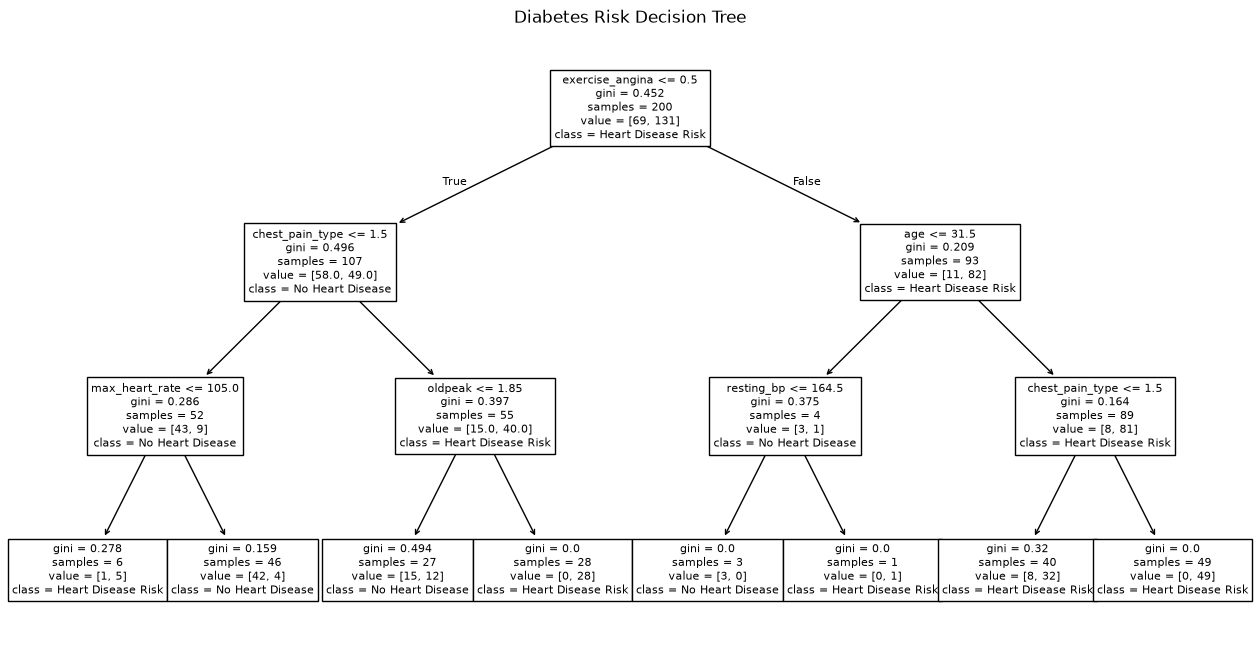

In [9]:
plt.figure(figsize=(16, 8))
plot_tree(clf, feature_names=feature_cols, class_names=['No Heart Disease', 'Heart Disease Risk'])
plt.title('Diabetes Risk Decision Tree')
plt.show

In [ ]:
# 1. Provide your new sample list with all 8 feature values in the correct order
custom_patient = [[
    58,   
    1,    
    2,   
    142,  
    265,  
    120,  
    1,    
    2.1   
]]

prediction_index = clf.predict(custom_patient)[0]

class_names = ['No Heart Disease', 'Heart Disease Risk']
predicted_label = class_names[prediction_index]

print(f"The model predicts: **{predicted_label}**")

The model predicts: **Heart Disease Risk**


C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [12]:
clf.score(X, y)

0.888